# Practical 05 – Diabetes Dataset Preprocessing and EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


In [2]:
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
path = Path('diabetes.csv')
if not path.exists():
    pd.read_csv(url, header=None, names=columns).to_csv(path, index=False)
df = pd.read_csv(path)


In [3]:
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    df[col] = df[col].replace(0, np.nan)


Shape: (768, 9) Missing values:
 Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  763.000000     733.000000     541.000000  394.000000   
mean      3.845052  121.686763      72.405184      29.153420  155.548223   
std       3.369578   30.535641      12.382158      10.476982  118.775855   
min       0.000000   44.000000      24.000000       7.000000   14.000000   
25%       1.000000   99.000000      64.000000      22.000000   76.250000   
50%       3.000000  117.000000      72.000000      29.000000  125.000000   
75%       6.000000  141.000000      80.000000      36.000000  190.000000   
max      17.000000  199.000000     122.000000      99.0000

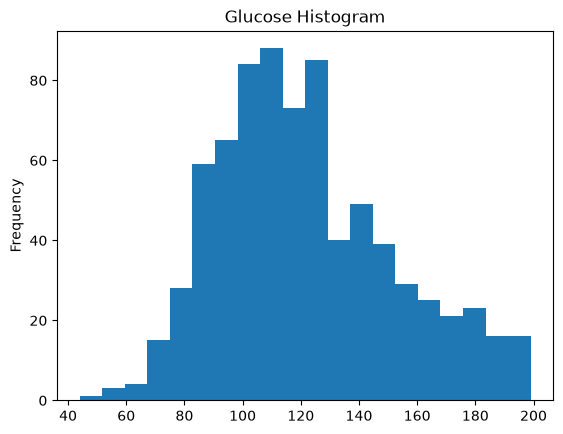

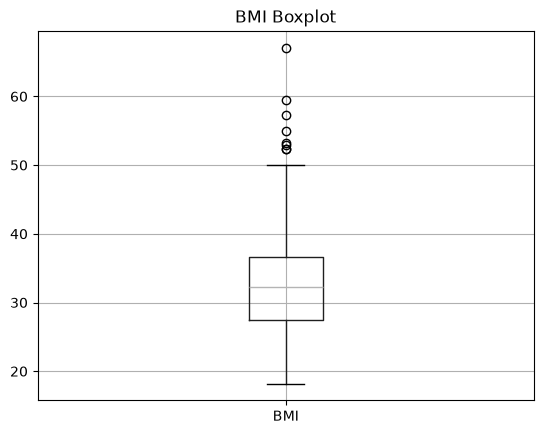

In [4]:
print('Shape:', df.shape, 'Missing values:\n', df.isna().sum())
print(df.describe())
df['Glucose'].plot.hist(bins=20, title='Glucose Histogram')
plt.show()
df.boxplot(column='BMI')
plt.title('BMI Boxplot')
plt.show()


In [5]:
X = df.drop(columns='Outcome')
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
pipe = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
print('Train:', pipe.fit_transform(X_train).shape, 'Test:', pipe.transform(X_test).shape)


Train: (614, 8) Test: (154, 8)
